# Star-cluster dynamics and a first protoplanetary-disk evaporation model

**Main question:** How does the initial virial ratio of a young stellar cluster change the UV irradiation environment and the survival of disks around low-mass stars?

**Run order:** imports → initial clusters → Ph4 evolution → UV proximity → UV exposure → assign disks → toy UV-driven disk mass loss → optional appendices.

All three initial clusters share masses/positions but have different **virial ratios** ($Q=0.25,\;0.5,\;0.75$). All three are evolved. We define disk hosts as stars with $M<2M_\odot$ and UV sources as stars with $M\geq8M_\odot$.

**Physical limitation:** The added disk evolution is an *illustrative* mass-budget model, not a calibrated external-photoevaporation model. It does not run VADER or SPH. The UV weights, mass-loss timescale and radius evolution are free parameters; do not interpret the output as a quantitative disk-survival prediction.


In [2]:
%matplotlib inline

from amuse.lab import *
from amuse.ic.fractalcluster import new_fractal_cluster_model
from amuse.ic.kroupa import new_kroupa_mass_distribution
from amuse.community.ph4.interface import ph4
from amuse.units import nbody_system
from cluster_tools import *
from matplotlib import pyplot as plt
import numpy as np
from make_disks import initialize_disk_population, evolve_disk_population

## 1. Build and inspect initial clusters

The clusters start with the same mass distribution and spatial configuration, with velocities scaled to the requested virial ratio. Disk hosts are defined here as stars with $M<2\,M_\odot$, and candidate strong-UV sources as stars with $M\geq8\,M_\odot$ (a simple threshold, not a full luminosity model).


Q=0.25: N=1000, hosts(<2 Msun)=962, UV sources(>=8 Msun)=3, Intermediate(2-8 Msun)=35, M_tot=532 Msun, R_vir=1.00 pc, Q=0.25
Q=0.5: N=1000, hosts(<2 Msun)=962, UV sources(>=8 Msun)=3, Intermediate(2-8 Msun)=35, M_tot=532 Msun, R_vir=1.00 pc, Q=0.50
Q=0.75: N=1000, hosts(<2 Msun)=962, UV sources(>=8 Msun)=3, Intermediate(2-8 Msun)=35, M_tot=532 Msun, R_vir=1.00 pc, Q=0.75


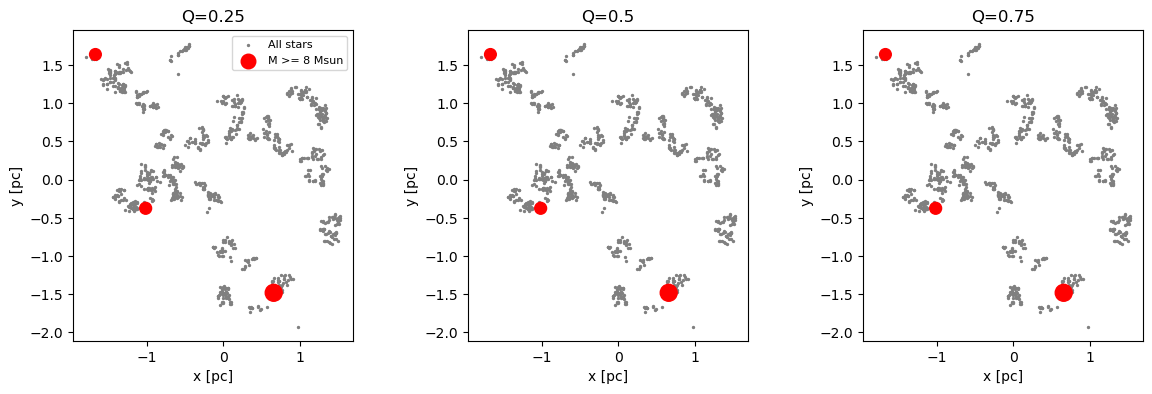

In [3]:
clusters = {
    f"Q={q}": make_cluster(r_vir=1.0 | units.pc, virial_ratio=q)
    for q in (0.25, 0.5, 0.75)
}

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, (stars, conv)) in zip(axes, clusters.items()):
    kinetic = stars.kinetic_energy().value_in(units.J)
    potential = stars.potential_energy().value_in(units.J)
    actual_q = kinetic / abs(potential)

    hosts = stars[stars.mass < (2 | units.MSun)]

    intermediate = stars[
        (stars.mass >= (2 | units.MSun)) &
        (stars.mass < (8 | units.MSun))
    ]

    massive = stars[stars.mass >= (8 | units.MSun)]
    uv_sources = stars[stars.mass >= (8 | units.MSun)]
    print(
        f"{name}: N={len(stars)}, hosts(<2 Msun)={len(hosts)}, "
        f"UV sources(>=8 Msun)={len(uv_sources)}, "
        f"Intermediate(2-8 Msun)={len(intermediate)}, "
        f"M_tot={stars.mass.sum().value_in(units.MSun):.0f} Msun, "
        f"R_vir={stars.virial_radius().value_in(units.pc):.2f} pc, "
        f"Q={actual_q:.2f}"
    )

    ax.scatter(stars.x.value_in(units.pc), stars.y.value_in(units.pc),
               s=2, c="grey", label="All stars")
    ax.scatter(uv_sources.x.value_in(units.pc),
               uv_sources.y.value_in(units.pc),
               s=20*np.sqrt(uv_sources.mass.value_in(units.MSun)),
               c="red", label="M >= 8 Msun")
    ax.set_title(name)
    ax.set_xlabel("x [pc]")
    ax.set_ylabel("y [pc]")
    ax.set_aspect("equal")
axes[0].legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()


## 2. Gravitational evolution with Ph4

Run the $Q=0.25$, $Q=0.5$, and $Q=0.75$ clusters independently. `evolve_gravity` provides lists of `(time, Particles)` snapshots. 


In [4]:
# Evolve every cluster with Ph4 (Q = 0.25 subvirial, 0.5 virial, 0.75 supervirial)
snapshot_sets = {}
for label, (stars, conv) in clusters.items():
    print(f"--- {label} ---")
    snapshot_sets[label] = evolve_gravity(stars, conv, n_snap=2)
    # Change the n_snap to 20+ once it runs once! 

# keep the old names so nothing else breaks
snaps25 = snapshot_sets["Q=0.25"]
snaps5  = snapshot_sets["Q=0.5"]
snaps75 = snapshot_sets["Q=0.75"]

--- Q=0.25 ---
relative error dE/E = 6.1e-05
--- Q=0.5 ---
relative error dE/E = 3.4e-04
--- Q=0.75 ---
relative error dE/E = 4.8e-04


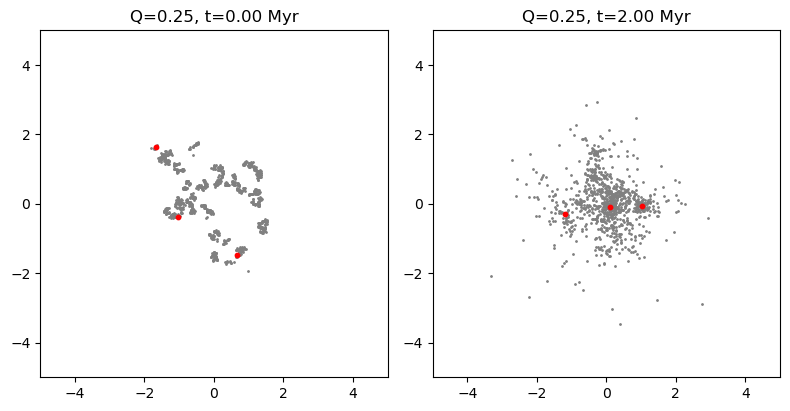

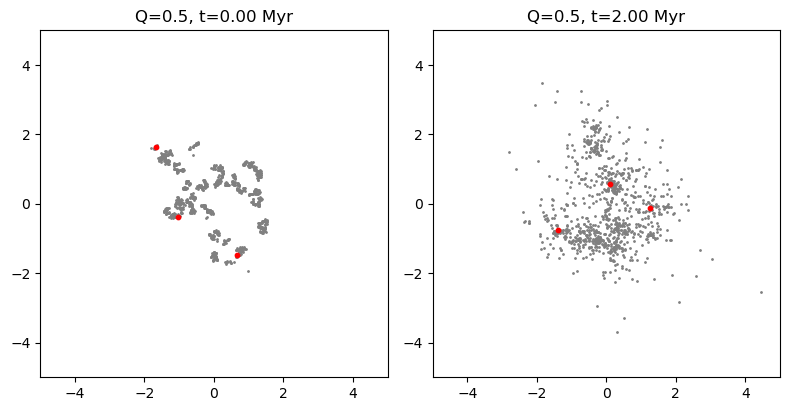

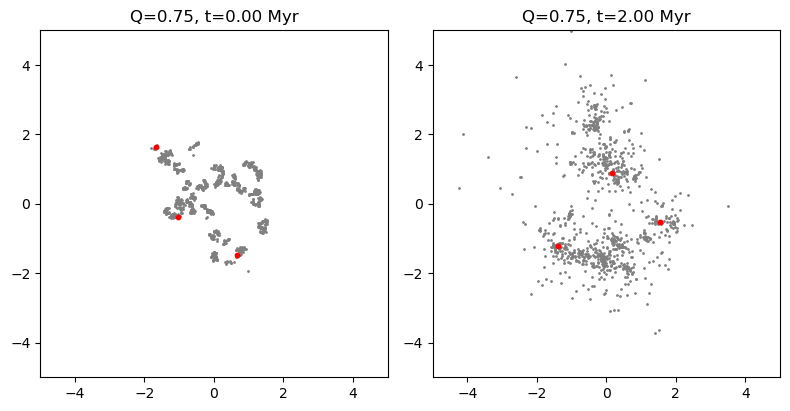

In [5]:
# Visualize four representative snapshots from each Ph4 run.
for label, history in snapshot_sets.items():
    selected = np.unique(np.linspace(0, len(history)-1, 4, dtype=int))
    fig, axes = plt.subplots(1, len(selected), figsize=(4*len(selected), 4))
    for ax, idx in zip(np.atleast_1d(axes), selected):
        t, snapshot = history[idx]
        uv_sources = snapshot[snapshot.mass >= (8 | units.MSun)]
        ax.scatter(snapshot.x.value_in(units.pc), snapshot.y.value_in(units.pc),
                   s=1, c="grey")
        ax.scatter(uv_sources.x.value_in(units.pc),
                   uv_sources.y.value_in(units.pc), s=10, c="red")
        ax.set_title(f"{label}, t={t.value_in(units.Myr):.2f} Myr")
        ax.set_xlim(-5, 5)
        ax.set_ylim(-5, 5)
        ax.set_aspect("equal")
    plt.tight_layout()
    plt.show()


## 3. UV-source proximity: initial conditions and evolution

**Left:** Cumulative distribution of distances from disk hosts to their nearest UV source. **Right:** Fraction of hosts within 0.1 pc over time, compared across evolved virial ratios. The 0.1 pc cutoff is only a diagnostic threshold, **not** a photoevaporation boundary.

Because initial positions are the same, expect nearly identical initial-distance curves for all three $Q$ values; the distinction should emerge during dynamical evolution.


Q=0.25: median nearest-source distance = 1.099 pc; within 0.1 pc = 2.70%
Q=0.5: median nearest-source distance = 1.099 pc; within 0.1 pc = 2.70%
Q=0.75: median nearest-source distance = 1.099 pc; within 0.1 pc = 2.70%


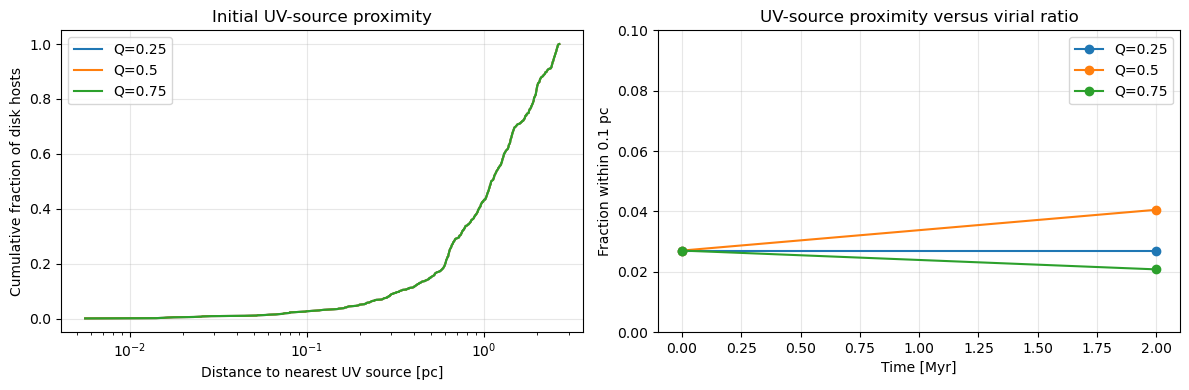

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Initial stellar positions: same for all Q, as expected.
for name, (stars, _) in clusters.items():
    distances = nearest_uv_distance(stars)
    sorted_d = np.sort(distances)
    cumulative = np.arange(1, len(sorted_d)+1) / len(sorted_d)
    ax[0].plot(sorted_d, cumulative, label=name)
    print(f"{name}: median nearest-source distance = {np.median(distances):.3f} pc; "
          f"within 0.1 pc = {np.mean(distances < 0.1):.2%}")

ax[0].set_xscale("log")
ax[0].set_xlabel("Distance to nearest UV source [pc]")
ax[0].set_ylabel("Cumulative fraction of disk hosts")
ax[0].set_title("Initial UV-source proximity")
ax[0].legend()
ax[0].grid(alpha=0.3)

# Time evolution: iterate over *each* list of (time, snapshot) pairs.
for label, history in snapshot_sets.items():
    t_myr = []
    close_fraction = []
    for t, snapshot in history:
        distances = nearest_uv_distance(snapshot)
        t_myr.append(t.value_in(units.Myr))
        close_fraction.append(np.mean(distances < 0.1))
    ax[1].plot(t_myr, close_fraction, "o-", label=label)

ax[1].set_xlabel("Time [Myr]")
ax[1].set_ylabel("Fraction within 0.1 pc")
ax[1].set_title("UV-source proximity versus virial ratio")
ax[1].set_ylim(0, 0.1)
ax[1].legend()
ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 4. Geometric UV exposure over time

Evaluate the **median** dimensionless exposure proxy among disk hosts at every saved snapshot. Compare the three Ph4 runs, not a nonexistent `snaps` variable. This is the input geometry for a future model that assigns UV luminosities and physical photoevaporation rates.


Q=0.25: median exposure at final snapshot = 3.38
Q=0.5: median exposure at final snapshot = 1.36
Q=0.75: median exposure at final snapshot = 0.939


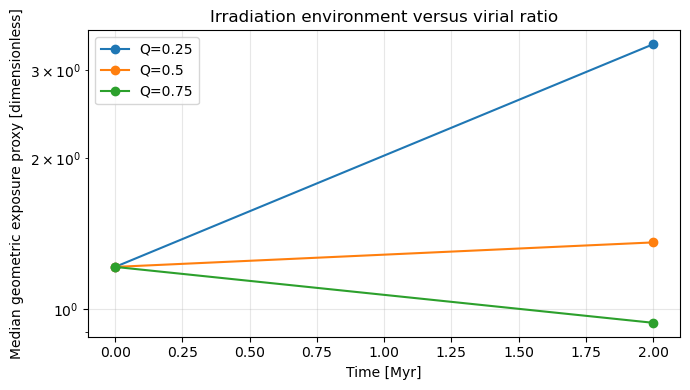

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))

for label, history in snapshot_sets.items():
    t_myr = []
    median_exposure = []
    for t, snapshot in history:
        values = exposure_proxy(snapshot)
        t_myr.append(t.value_in(units.Myr))
        median_exposure.append(np.median(values))
    ax.plot(t_myr, median_exposure, "o-", label=label)
    print(f"{label}: median exposure at final snapshot = {median_exposure[-1]:.3g}")

ax.set_yscale("log")
ax.set_xlabel("Time [Myr]")
ax.set_ylabel("Median geometric exposure proxy [dimensionless]")
ax.set_title("Irradiation environment versus virial ratio")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 5. Assign a disk to low-mass stars

We create **one numerical disk per selected low-mass host**, stored as its initial mass and radius. By default, half of the stars with $M<2M_\odot$ receive disks; each disk starts with $M_{d,0}=0.05M_*$ and $R_{d,0}=100$ AU. These are configurable assumptions. We reuse the same random seed for all three $Q$ runs so the same stellar *indices* receive disks.

`add_disks()` in `make_disks.py` can separately generate physical gas particles for demonstration, but those are **not** being evolved by the toy model below.

In [8]:
from make_disks import initialize_disk_population, evolve_disk_population

disk_populations = {}

for label, history in snapshot_sets.items():
    initial_stars = history[0][1]
    disks = initialize_disk_population(
        initial_stars,
        fraction=0.5,
        disk_mass_fraction=0.05,
        radius_au=100.0,
        seed=123,
    )
    disk_populations[label] = disks

    print(f"{label}: {len(disks['host_indices'])} disks, "
        f"total initial disk mass = {disks['initial_mass_msun'].sum():.3f} Msun")

assert np.array_equal(disk_populations["Q=0.25"]["host_indices"],
                      disk_populations["Q=0.5"]["host_indices"])


Q=0.25: 481 disks, total initial disk mass = 8.268 Msun
Q=0.5: 481 disks, total initial disk mass = 8.268 Msun


## 6. Evolve disks with a simple UV-dependent erosion law

We compute the (dimensionless) proxy $I_i=\sum_{j,M_j\geq8M_\odot}(M_j/8M_\odot)^{3.5}(1\,\mathrm{pc}/d_{ij})^2$ for each disk host. For an **illustrative toy model**, let $dM_d/dt=-(M_d/\tau)\sqrt{I_i/I_\mathrm{ref}}$, with $\tau=1$ Myr and $I_\mathrm{ref}=100$. The mass decreases gradually, based on the exposure history. We also visualize an **assumed** disk shrinkage $R_d/R_{d,0}=(M_d/M_{d,0})^{1/2}$.

These coefficients are **not calibrated FUV/photoevaporation physics**. This stage tests the bookkeeping, host tracking and relationship to cluster dynamics. A published FRIED mass-loss grid and stellar FUV luminosities are needed for quantitative predictions.

Q=0.25: median mass remaining at 2.0 Myr = 0.1%
Q=0.5: median mass remaining at 2.0 Myr = 0.5%


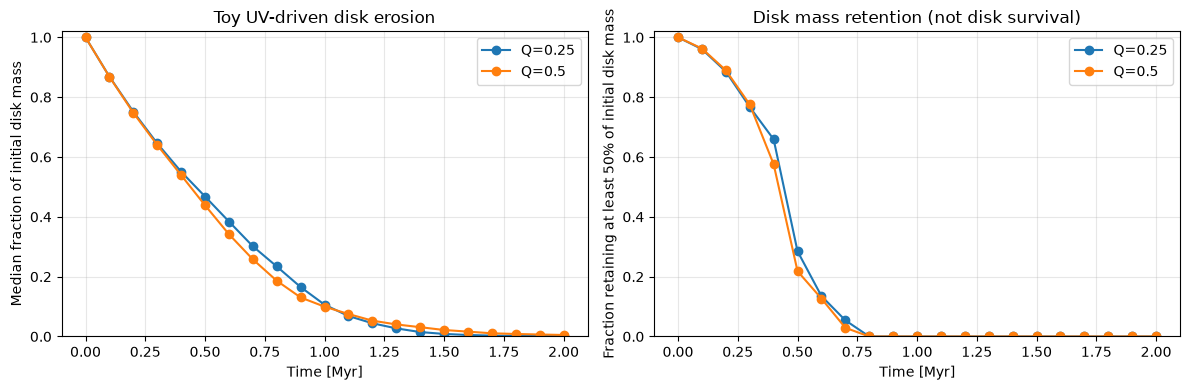

In [12]:
disk_results = {}
for label, history in snapshot_sets.items():
    result = evolve_disk_population(
        history,
        disk_populations[label],
        reference_intensity=100.0,
        erosion_timescale_myr=1.0,
        radius_exponent=0.5,
    )
    disk_results[label] = result
    print(f"{label}: median mass remaining at {result['times_myr'][-1]:.1f} Myr "
          f"= {np.median(result['remaining_fraction'][-1]):.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, result in disk_results.items():
    times = result["times_myr"]
    remaining = result["remaining_fraction"]
    axes[0].plot(times, np.median(remaining, axis=1), "o-", label=label)
    axes[1].plot(times, np.mean(remaining >= 0.5, axis=1), "o-", label=label)

axes[0].set_ylabel("Median fraction of initial disk mass")
axes[1].set_ylabel("Fraction retaining at least 50% of initial disk mass")
for ax in axes:
    ax.set_xlabel("Time [Myr]")
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_title("Toy UV-driven disk erosion")
axes[1].set_title("Disk mass retention (not disk survival)")
plt.tight_layout()
plt.show()

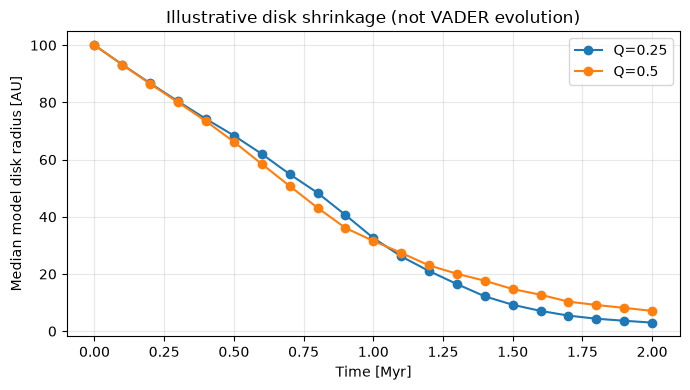

In [13]:
# Optional diagnostic: compare the median disk radius, using the toy shrinkage law.
fig, ax = plt.subplots(figsize=(7, 4))
for label, result in disk_results.items():
    ax.plot(result["times_myr"], np.median(result["radius_au"], axis=1),
            "o-", label=label)
ax.set_xlabel("Time [Myr]")
ax.set_ylabel("Median model disk radius [AU]")
ax.set_title("Illustrative disk shrinkage (not VADER evolution)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## Appendix A — stand-alone fractal-cluster initialization experiment

This separate experiment explores AMUSE's `new_fractal_cluster_model` and is not used by the `make_cluster` / Ph4 analysis above. The original sequence is preserved here at the end so it does not interrupt the main workflow.


In [9]:
# Independent exploratory model; not used in the main Ph4 calculations above.
n_stars = 1000
mass_min = 0.01 | units.MSun
mass_max = 100 | units.MSun
masses_kroupa = new_kroupa_mass_distribution(
    n_stars, mass_min=mass_min, mass_max=mass_max
)


In [10]:
fractal_dimension = 2.0
length_scale = 1.0 | units.parsec
mass_scale = masses_kroupa.sum()

# This converter sets the N-body mass and length scales in physical units.
fractal_converter = nbody_system.nbody_to_si(mass_scale, length_scale)
star_cluster = new_fractal_cluster_model(
    n_stars, fractal_dimension=fractal_dimension, convert_nbody=fractal_converter
)

star_cluster.mass = masses_kroupa
star_cluster.radius = 0.5 | units.au
star_cluster.move_to_center()
print(star_cluster[:5])


                 key         mass       radius           vx           vy           vz            x            y            z
                   -           kg            m    m * s**-1    m * s**-1    m * s**-1            m            m            m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
14947223167578598089    7.952e+28    7.480e+10   -7.539e+01    2.459e+02    3.272e+02    1.828e+16    2.191e+14    2.030e+16
13612618829573974083    2.743e+29    7.480e+10   -1.897e+01   -1.147e+03    2.433e+02    3.754e+16    9.989e+15   -1.004e+16
10238734878878607023    1.132e+30    7.480e+10   -7.555e+02    9.024e+02   -3.058e+02   -8.944e+15    8.293e+15   -1.713e+16
 5484842705984455938    5.729e+29    7.480e+10   -7.218e+02    9.682e+02   -3.198e+02   -8.602e+15    1.543e+16   -1.863e+16
10579299507339877070    8.037e+29    7.480e+10    4.743e+02    5.757e+02   -3.724e+02    1.631e+16   -1.294e+16    2.780e+16


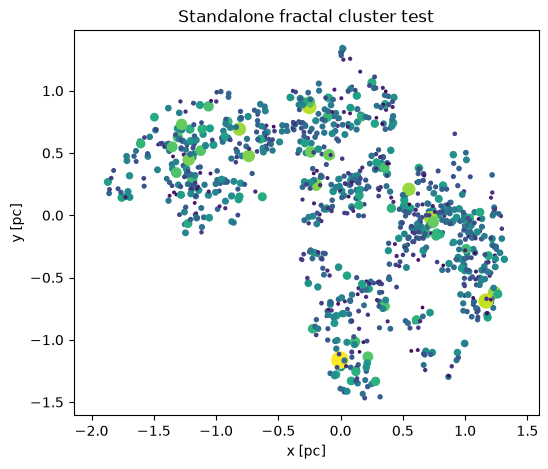

In [11]:
plt.figure(figsize=(6, 5))
plt.scatter(
    star_cluster.x.value_in(units.pc),
    star_cluster.y.value_in(units.pc),
    c=np.log10(star_cluster.mass.value_in(units.MSun)),
    s=25.0*np.sqrt(star_cluster.mass.value_in(units.MSun)),
)
plt.xlabel("x [pc]")
plt.ylabel("y [pc]")
plt.title("Standalone fractal cluster test")
plt.axis("equal")
plt.show()


## Appendix B — experimental protoplanetary-disk code (not yet coupled)

These blocks were in the source notebook as exploratory cells. They are kept **as reference snippets, not executable cells**, because they are not part of the current Ph4/UV analysis. In particular, the sample code refers to an undefined `particles_fractal`, creates disks without validated host assignment, or starts VADER without a configured model. Making them runnable would be a separate scientific development task.


### Disk-helper draft

This original draft is preserved verbatim; it was commented out in the supplied notebook.

```python
from amuse.datamodel import Particles
from amuse.ext.protodisk import ProtoPlanetaryDisk
'''

def make_disk(star, n_disk=1000, r_in=1.0, r_out=100.0, disk_frac=0.01): 
    """Return a gas disk centred on `star`. r_in and r_out are in AU.""" 
    converter = nbody_system.nbody_to_si(star.mass, r_in | units.AU) 
    disk = ProtoPlanetaryDisk(n_disk, convert_nbody=converter, Rmin=1.0, Rmax=r_out / r_in,discfraction=disk_frac).result 

    disk.position += star.position # move disk onto the star 
    disk.velocity += star.velocity 
    disk.host_key = star.key # tag disk particles with their star 
    return disk 

disks = Particles() 
for star in particles_fractal: 
    if star.mass < 2 | units.MSun: 
        disks.add_particles(make_disk(star))
    else: 
        None
'''
```


### VADER initialization test

Starting `Vader()` alone is not yet disk evolution. This snippet is preserved but not executed on **Run All**.

```python
from amuse.community.vader.interface import Vader

Vader()
```
